# 附录 A1 · 主场优势 γ（T3.5 / T3.6 / T3.7）

对应 `08_小组分工实施方案_v1.3.md` §3.3 与 `roles/M3_结构化统计模型.md` §4。
**A1 是描述性附录，不做因果主张。**

## 口径（先定死，避免看图选参数）

- 每季一个 γ_s：用该联赛**截至该季结束**的全部比赛拟合（expanding，不是 8 个折点）；
- 时间衰减固定 **ξ = 0.0019**（一年半衰期）：22 个点必须同一个平滑强度，否则趋势里会混进调参噪声；
- **不挂 τ**：A1 不逐季选 ρ，否则同样的调参噪声会渗进趋势；
- 标准误取观测信息矩阵（nll 的解析 Hessian 对减参 θ 做 `J'HJ`），γ 的方差已经对"α/β 也估不准"做了边缘化；
- 22 个点的窗口彼此重叠 ⇒ 误差**正相关**；WLS 按独立误差算的区间**偏窄**（AR(1) 仿真实测：ρ=0.5/0.9 时真实 SD 是朴素 SE 的 1.7/3.3 倍，见 `products/tables/tA1_trend_se_inflation.csv`），报告里照实写。

## 数据来源（由 `src/models/` 生成，本 notebook 只读不重算）

| 文件 | 生成命令 | 内容 |
|---|---|---|
| `results/logs/gamma_by_season.csv` | `python -m src.models.a1_gamma` | 22 季 × 6 联赛 γ / se |
| `results/logs/gamma_empty_window.csv` | `python -m src.models.a1_empty` | 3 窗 × 6 联赛 γ / se |
| `results/logs/a1_extrapolation.csv` | `python -m src.models.a1_extrapolation` | 2024/25 外推对照 |

In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd

ROOT = Path.cwd()
while not (ROOT / "results").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.models.a1_gamma import LEAGUES, trend
from src.models.a1_empty import WINDOWS, pooled, compare, draw

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)

wide = pd.read_csv(ROOT / "results/logs/gamma_by_season.csv")
empty = pd.read_csv(ROOT / "results/logs/gamma_empty_window.csv")
extra = pd.read_csv(ROOT / "results/logs/a1_extrapolation.csv")
print("γ 逐季", wide.shape, "| 空场窗", empty.shape, "| 外推", extra.shape)

γ 逐季 (22, 16) | 空场窗 (18, 12) | 外推 (6, 15)


## A1-a · 22 季逐季轨迹

每点是"用该联赛截至该季结束（含）的全部比赛、ξ=0.0019、无 τ"拟合出的 γ。
趋势线用 WLS（权重 `1/se²`）；LOWESS 只用来画图，不参与任何数字。

In [2]:
show = wide[["season", "gamma_pooled", "se_pooled"] + [f"gamma_{lg}" for lg in LEAGUES]].copy()
show.columns = ["season", "pooled", "se"] + list(LEAGUES)
print(show.round(3).to_string(index=False))

print("\n趋势（WLS γ ~ 年，权重 1/se²）")
rows = []
for lg in LEAGUES:
    tr = trend(wide, f"gamma_{lg}", f"se_{lg}")
    rows.append([lg, tr["slope_per_year"], tr["lo95"], tr["hi95"]])
tr = trend(wide)
rows.append(["pooled", tr["slope_per_year"], tr["lo95"], tr["hi95"]])
tbl = pd.DataFrame(rows, columns=["league", "slope/yr", "lo95", "hi95"])
tbl["per decade"] = tbl["slope/yr"] * 10
print(tbl.round(5).to_string(index=False))
print(f"\npooled：每十年 {tr['slope_per_decade']:+.3f}"
      f"（95% CI {tr['lo95_decade']:+.3f} 到 {tr['hi95_decade']:+.3f}）；"
      f"六联赛同向 {'是' if all(trend(wide, f'gamma_{lg}', f'se_{lg}')['slope_per_year'] < 0 for lg in LEAGUES) else '否'}")

 season  pooled    se    E0   SP1    I1    D1    F1    N1
2003/04   0.321 0.027 0.270 0.216 0.288 0.463 0.426 0.292
2004/05   0.329 0.019 0.325 0.302 0.289 0.361 0.471 0.245
2005/06   0.316 0.016 0.350 0.260 0.286 0.319 0.427 0.266
2006/07   0.305 0.014 0.356 0.217 0.321 0.222 0.387 0.336
2007/08   0.328 0.012 0.338 0.267 0.336 0.306 0.374 0.353
2008/09   0.324 0.011 0.308 0.282 0.332 0.320 0.327 0.384
2009/10   0.336 0.010 0.391 0.325 0.354 0.233 0.321 0.387
2010/11   0.333 0.009 0.356 0.356 0.310 0.249 0.312 0.404
2011/12   0.337 0.009 0.315 0.394 0.323 0.282 0.332 0.367
2012/13   0.299 0.008 0.267 0.369 0.291 0.223 0.322 0.314
2013/14   0.295 0.008 0.271 0.376 0.274 0.217 0.308 0.319
2014/15   0.282 0.008 0.290 0.347 0.250 0.266 0.280 0.257
2015/16   0.272 0.007 0.258 0.359 0.266 0.243 0.280 0.216
2016/17   0.285 0.007 0.271 0.311 0.255 0.278 0.324 0.271
2017/18   0.271 0.007 0.285 0.307 0.219 0.287 0.285 0.241
2018/19   0.268 0.007 0.257 0.285 0.217 0.272 0.298 0.282
2019/20   0.25

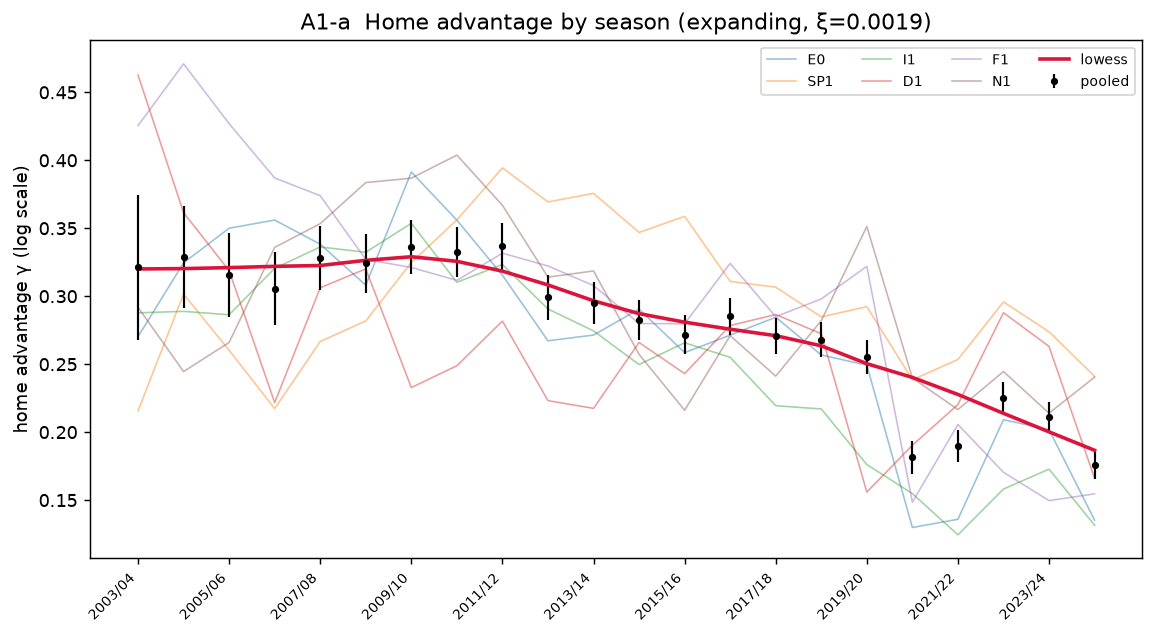

In [3]:
import matplotlib.pyplot as plt
from statsmodels.nonparametric.smoothers_lowess import lowess

x = np.arange(len(wide))
fig, ax = plt.subplots(figsize=(9, 5))
for lg in LEAGUES:
    ax.plot(x, wide[f"gamma_{lg}"], lw=0.9, alpha=0.45, label=lg)
ax.errorbar(x, wide["gamma_pooled"], yerr=1.96 * wide["se_pooled"],
            fmt="o", ms=3, lw=1.2, color="black", label="pooled")
sm = lowess(wide["gamma_pooled"], x, frac=0.45)
ax.plot(sm[:, 0], sm[:, 1], color="crimson", lw=2, label="lowess")
ax.set_xticks(x[::2])
ax.set_xticklabels(wide["season"][::2], rotation=45, ha="right", fontsize=8)
ax.set_ylabel("home advantage γ (log scale)")
ax.set_title("A1-a  Home advantage by season (expanding, ξ=0.0019)")
ax.legend(ncol=4, fontsize=8)
fig.tight_layout()
fig.savefig(ROOT / "products" / "figures" / "fig_a1_gamma.png", dpi=150)
plt.show()

## A1-b · 空场期对照（按日期切窗）

**按日期切，不按赛季整块切**：2019/20 是赛季中途断的（2020-03 停摆、2020-06 复赛），
按赛季切会把"有观众的上半季"和"空场的下半季"混进同一个数。

| window | 日期 | 覆盖 |
|---|---|---|
| pre | 2018-08-01 → 2020-06-01 | 2018/19 + 2019/20 停摆前 |
| empty | 2020-06-01 → 2021-08-01 | 复赛 + 整个 2020/21 |
| post | 2021-08-01 → 2023-07-01 | 2021/22 + 2022/23 |

窗内拟合只用该窗比赛，**ξ=0**（窗口本身就是切片，再叠衰减等于在窗内挑近的）、不挂 τ。
六个联赛各自拟合再逆方差合并（联赛之间没有交叉比赛，拼在一起拟合会依赖"各联赛水平相同"）。
窗与窗没有共同比赛，差值 SE 取 `sqrt(se_a² + se_b²)`。

**只作描述性对照，不称自然实验**：同期还有赛季腰斩、赛程压缩、换人规则变化。

In [4]:
win = {name: pooled(empty.loc[empty["window"] == name]) for name, _, _ in WINDOWS}
tbl = pd.DataFrame([{"window": n, **w} for n, w in win.items()])
tbl["home bonus"] = np.exp(tbl["gamma"]) - 1
print(tbl.round(4).to_string(index=False))

cmp = pd.DataFrame(compare(win))
print("\n差值（窗与窗无共同比赛，SE 取平方和）")
print(cmp.round(4).to_string(index=False))

piv = empty.pivot_table(index="league", columns="window", values="gamma")
piv["empty−pre"] = piv["empty"] - piv["pre"]
piv["empty−post"] = piv["empty"] - piv["post"]
print("\n逐联赛（防止「合并显著」掩盖某个联赛反向）")
print(piv.round(3).to_string())

d = wide["gamma_pooled"].diff()
normal = d.drop(index=[17, 18]).dropna()      # 去掉 19/20→20/21、20/21→21/22 两跳
delta = win["empty"]["gamma"] - win["pre"]["gamma"]
print(f"\n普通逐年波动 SD = {normal.std():.4f}（{len(normal)} 个跳变），"
      f"空场 Δ = {delta:+.4f} = {abs(delta) / normal.std():.1f} 倍 SD")

window  gamma     se  n_matches  n_leagues  n_converged  home bonus
   pre 0.2591 0.0197       3716          6            6      0.2957
 empty 0.1201 0.0238       2505          6            6      0.1276
  post 0.2288 0.0184       4264          6            6      0.2571

差值（窗与窗无共同比赛，SE 取平方和）
    contrast    diff     se    lo95    hi95     pct
 empty − pre -0.1390 0.0309 -0.1995 -0.0784 -0.1297
empty − post -0.1087 0.0301 -0.1677 -0.0497 -0.1030

逐联赛（防止「合并显著」掩盖某个联赛反向）
window  empty   post    pre  empty−pre  empty−post
league                                            
D1      0.169  0.303  0.180     -0.011      -0.133
E0      0.058  0.221  0.218     -0.161      -0.163
F1      0.025  0.188  0.328     -0.303      -0.163
I1      0.145  0.149  0.173     -0.027      -0.003
N1      0.139  0.231  0.368     -0.229      -0.092
SP1     0.179  0.296  0.301     -0.122      -0.117

普通逐年波动 SD = 0.0177（19 个跳变），空场 Δ = -0.1390 = 7.8 倍 SD


图已写入 products\figures\fig_a1_empty_stadium.png


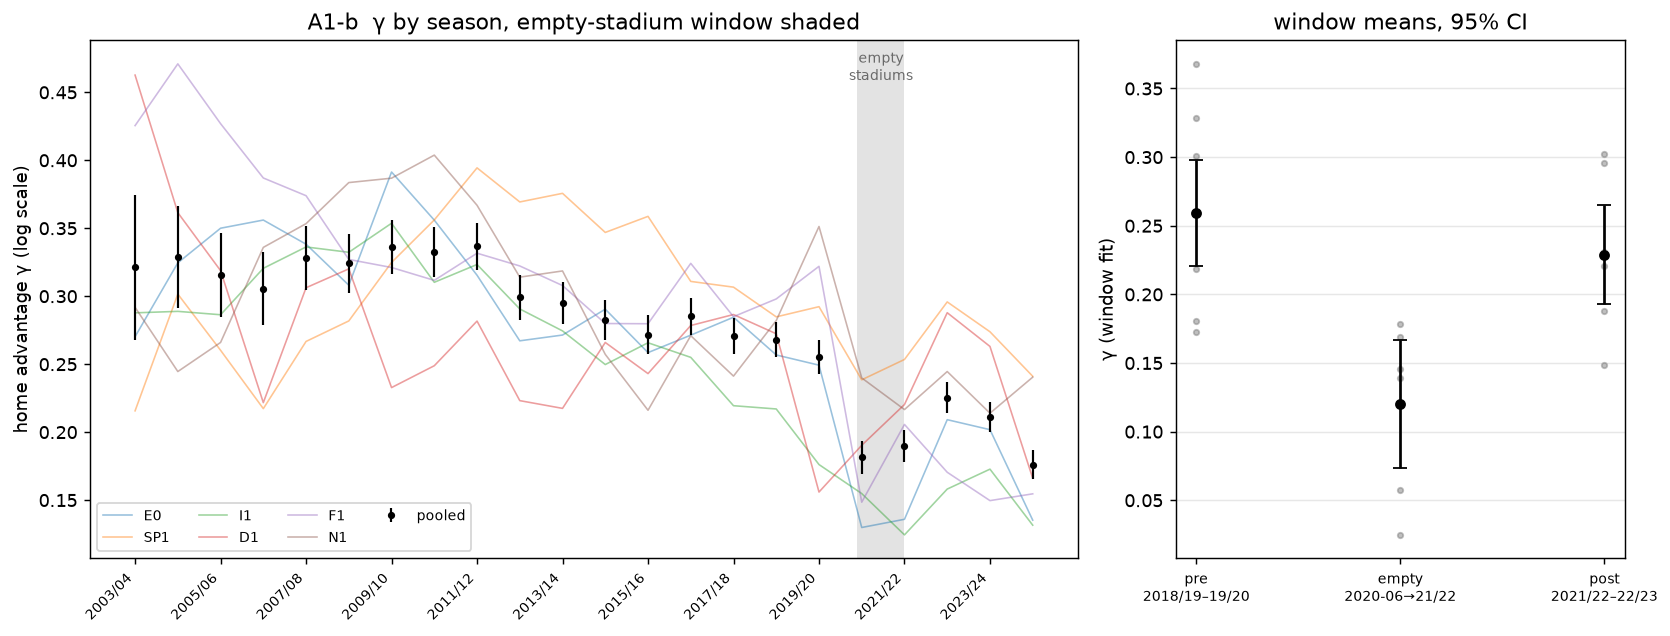

In [5]:
draw(wide, win, empty)
plt.show()

## A1-c · 把主场优势当常数的代价（可选）

每个联赛用**严格早于 2024/25** 的比赛估一次参数（ξ=0.0019），α/β/μ 冻结，只允许 γ 在
2024/25 赛内一维重估（in-sample 上界），比较两种做法的 log loss 与 p_home 偏差。

口径提醒：`γ_oracle` 是在 α/β 冻结下的一维重估，会吸收球队强弱漂移——它衡量的是
"这个 γ 值配这套 α/β 能多准"，不是干净的 HA 估计。

In [6]:
cols = ["league", "n_test", "gamma_stale", "gamma_oracle", "dgamma",
        "ll_stale", "ll_oracle", "dll", "p_home_stale", "home_share_actual"]
print(extra[cols].round(4).to_string(index=False))

n = extra["n_test"].to_numpy(float)
ll_s = float((extra["ll_stale"] * n).sum() / n.sum())
ll_o = float((extra["ll_oracle"] * n).sum() / n.sum())
bias = float((extra["p_home_stale"] - extra["home_share_actual"]).mean())
print(f"\n合并 Δlogloss {ll_s - ll_o:+.4f} nats；Δγ {extra['dgamma'].mean():+.3f}；"
      f"p_home 偏 {bias:+.3f}")
print(f"把 γ 当常数更差的联赛 {int((extra['dll'] > 0).sum())}/6；"
      f"γ_stale 偏高 {int((extra['dgamma'] > 0).sum())}/6")

league  n_test  gamma_stale  gamma_oracle  dgamma  ll_stale  ll_oracle     dll  p_home_stale  home_share_actual
    E0     380       0.2018        0.1172  0.0847    1.0196     1.0165  0.0031        0.4475             0.4079
   SP1     380       0.2738        0.2989 -0.0251    0.9830     0.9830 -0.0000        0.4457             0.4447
    I1     380       0.1728        0.1206  0.0522    0.9759     0.9752  0.0007        0.4241             0.3974
    D1     306       0.2631        0.1666  0.0965    1.0247     1.0147  0.0100        0.4718             0.3856
    F1     306       0.1496        0.2516 -0.1020    0.9841     0.9801  0.0040        0.4208             0.4673
    N1     306       0.2139        0.2326 -0.0187    0.9694     0.9693  0.0001        0.4521             0.4542

合并 Δlogloss +0.0028 nats；Δγ +0.015；p_home 偏 +0.017
把 γ 当常数更差的联赛 5/6；γ_stale 偏高 3/6


## 写进报告的三句话（数字由上面的 CSV 现算，不手抄）

下面这个 cell 打印的三段就是附录 A 的正文骨架；改动任何一个口径都请重跑，
**不要手动改数字**。

In [7]:
tr = trend(wide)
e, p, q = win["empty"], win["pre"], win["post"]
print(f"1) 二十年里，合并的主场加成从 {np.exp(wide['gamma_pooled'].iloc[0]) - 1:.0%} "
      f"降到 {np.exp(wide['gamma_pooled'].iloc[-1]) - 1:.0%}，斜率每十年 "
      f"{tr['slope_per_decade']:+.3f}（95% CI {tr['lo95_decade']:+.3f} 到 "
      f"{tr['hi95_decade']:+.3f}），六个联赛分看同向。")
print(f"2) 空场窗（2020-06 → 2021-08，按日期切）γ={e['gamma']:.3f}，比之前两季 "
      f"{p['gamma']:.3f} 低 {p['gamma'] - e['gamma']:.3f}，比之后两季 {q['gamma']:.3f} "
      f"低 {q['gamma'] - e['gamma']:.3f}；六个联赛同向，幅度约为普通逐年波动的 "
      f"{abs(p['gamma'] - e['gamma']) / normal.std():.1f} 倍。")
print(f"3) 把 γ 当常数外推 2024/25，合并 log loss 多 {ll_s - ll_o:+.4f} nats、p_home "
      f"多报 {bias:+.3f}——方向与衰退一致，但逐联赛只有 "
      f"{int((extra['dgamma'] > 0).sum())}/6，说明这是趋势不是单调律。")

1) 二十年里，合并的主场加成从 38% 降到 19%，斜率每十年 -0.090（95% CI -0.096 到 -0.084），六个联赛分看同向。
2) 空场窗（2020-06 → 2021-08，按日期切）γ=0.120，比之前两季 0.259 低 0.139，比之后两季 0.229 低 0.109；六个联赛同向，幅度约为普通逐年波动的 7.8 倍。
3) 把 γ 当常数外推 2024/25，合并 log loss 多 +0.0028 nats、p_home 多报 +0.017——方向与衰退一致，但逐联赛只有 3/6，说明这是趋势不是单调律。


## 四条必须写进图注 / 正文的 caveat

1. **区间偏窄**：22 个点用重叠窗口估，误差正相关；WLS 按独立误差给的 CI 偏窄（仿真：ρ=0.5/0.9 时真实 SD 是朴素 SE 的 1.7/3.3 倍）。走势的符号与显著性不受影响。
2. **空场期不是自然实验**：只有一个空场季，同期还有赛季腰斩、赛程压缩、换人规则变化，只做描述性对照。
3. **趋势不是单调律**：合并 γ 从 2020/21 的 0.182 升到 2022/23 的 0.225 再降到 2024/25 的 0.176；末季只有 F1、N1 两家回升（2/6），SP1 的末季水平仍高于首季，但已从 2022/23 的 0.296 回落。
4. **ξ 是固定的**：若要改 ξ，必须 22 个点一起改并重跑趋势，不能逐季挑让斜率更好看的值。